## Part A: Supervised Baseline with Limited Labels

**Objective**
Train a ResNet18 from scratch (no pretrained weights) using only the 500 labeled images, and measure how well it does on the test set. This is the baseline for the whole assignment. Parts B and C ask whether pretraining on unlabeled images can beat it.

**Setup**
| Item | Choice |
|---|---|
| Backbone | ResNet18, random initialization |
| Training data | 500 labeled images (50 per class), same subset for every part |
| Training style | Full network trained on the labels, all layers updating |
| Epochs | About 10 to 15 |
| Evaluation | Accuracy on the full 8,000 image test set |

**Question this part answers**
How far can a network get when it only sees 500 labeled images and has nothing else to learn from?

**What to expect**
With so few labels, a ResNet18 trained from scratch tends to overfit. Training accuracy will climb quickly while test accuracy stays low. That gap is the problem the self supervised methods in Parts B and C are trying to fix.

**Output**
Final test accuracy, reported along with the training curve and the encoder weights saved for the nearest neighbor search in Part D.

In [1]:
import random, numpy as np, torch

SID4  = 2122  
SEED  = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")

SID4=2122, SEED=2122, SLICE=122, HP_ID=4, CLS_A=2, CLS_B=8


## Dataset: STL-10

STL-10 is an image dataset built for learning from unlabeled data. It has 10 classes: airplane, bird, car, cat, deer, dog, horse, monkey, ship, truck. All images are 96x96 RGB, which is larger than CIFAR-10 (32x32), so objects are easier to see but training costs more compute.

| Split | Images | Labels | Use in this assignment |
|---|---|---|---|
| train | 5,000 (500 per class) | Yes | Only 10% (500 images) is used for Parts A, B and C |
| test | 8,000 (800 per class) | Yes | Test accuracy and the nearest neighbor search in Part D |
| unlabeled | 100,000 | No | Rotation pretraining (Part B) and SimCLR (Part C, 20,000 image subset) |

**Things worth knowing**
- The labeled train set is small on purpose. The dataset is meant to test how well a model learns from unlabeled data when labels are scarce.
- The unlabeled images come from a wider pool than the 10 classes, so some show other animals and vehicles that are not in the labeled set. The encoder has to learn general features, not just class specific ones.
- The test set is much bigger than the train set (8,000 vs 5,000), so test accuracy is a fairly stable measurement.

**Labeled subset used here**
50 images per class (500 total), chosen with SEED so the subset is balanced and reproducible. The indices are saved in `subset_idx.npy`, and the same 500 images are used in Parts A, B and C so the comparison is fair.

In [2]:
import os, tarfile
import torchvision
import numpy as np

ROOT = "./data"
TAR_PATH = "./data/stl10_binary.tar.gz"   # change this to where your downloaded tar file is

# Extract only if the folder isn't there yet
if not os.path.isdir(os.path.join(ROOT, "stl10_binary")):
    os.makedirs(ROOT, exist_ok=True)
    with tarfile.open(TAR_PATH) as tar:
        tar.extractall(ROOT)

print(os.listdir(os.path.join(ROOT, "stl10_binary")))

# download=False since the files are already local
train_ds = torchvision.datasets.STL10(ROOT, split="train", download=False)
test_ds  = torchvision.datasets.STL10(ROOT, split="test", download=False)
unlab_ds = torchvision.datasets.STL10(ROOT, split="unlabeled", download=False)

print("train:", len(train_ds), "test:", len(test_ds), "unlabeled:", len(unlab_ds))
classes = train_ds.classes
print(classes)

# 10% labeled subset: 50 images per class, chosen with SEED
rng = np.random.RandomState(SEED)
labels = np.array(train_ds.labels)
subset_idx = []
for c in range(10):
    idx_c = np.where(labels == c)[0]
    subset_idx.extend(rng.choice(idx_c, 50, replace=False).tolist())
subset_idx = np.array(sorted(subset_idx))

print("subset size:", len(subset_idx))
print("per class counts:", np.bincount(labels[subset_idx]))
np.save("subset_idx.npy", subset_idx)

['class_names.txt', 'fold_indices.txt', 'test_X.bin', 'test_y.bin', 'train_X.bin', 'train_y.bin', 'unlabeled_X.bin']
train: 5000 test: 8000 unlabeled: 100000
['airplane', 'bird', 'car', 'cat', 'deer', 'dog', 'horse', 'monkey', 'ship', 'truck']
subset size: 500
per class counts: [50 50 50 50 50 50 50 50 50 50]


### Transforms and loaders

In [3]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

MEAN, STD = (0.4467, 0.4398, 0.4066), (0.2603, 0.2566, 0.2713)

train_tf = T.Compose([
    T.RandomCrop(96, padding=8),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
test_tf = T.Compose([
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

# Same files as before, just with transforms attached
train_aug  = torchvision.datasets.STL10(ROOT, split="train", download=False, transform=train_tf)
train_plain = torchvision.datasets.STL10(ROOT, split="train", download=False, transform=test_tf)
test_set   = torchvision.datasets.STL10(ROOT, split="test",  download=False, transform=test_tf)

subset_idx = np.load("subset_idx.npy")

g = torch.Generator().manual_seed(SEED)
sup_train_loader = DataLoader(Subset(train_aug, subset_idx), batch_size=64,
                              shuffle=True, num_workers=2, generator=g)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)

print("train subset:", len(sup_train_loader.dataset), "test:", len(test_loader.dataset))

device: cuda
train subset: 500 test: 8000


### ResNet18 and training loop

In [6]:
import time
from torchvision.models import resnet18

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

EPOCHS_A = 15

model_a = resnet18(weights=None, num_classes=10).to(device)   # no pretrained weights
opt = torch.optim.Adam(model_a.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        total += y.size(0)
    return correct / total

hist_a = {"train_loss": [], "train_acc": [], "test_acc": []}

for epoch in range(1, EPOCHS_A + 1):
    model_a.train()
    run_loss = correct = total = 0
    for x, y in sup_train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        out = model_a(x)
        loss = loss_fn(out, y)
        loss.backward()
        opt.step()
        run_loss += loss.item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += y.size(0)
    tr_loss, tr_acc = run_loss / total, correct / total
    te_acc = evaluate(model_a, test_loader)
    hist_a["train_loss"].append(tr_loss); hist_a["train_acc"].append(tr_acc); hist_a["test_acc"].append(te_acc)
    print(f"{time.strftime('%H:%M:%S')} epoch {epoch:2d} | loss {tr_loss:.3f} | train acc {tr_acc:.3f} | test acc {te_acc:.3f}")

torch.save(model_a.state_dict(), "resnet18_supervised.pt")
print("Part A final test accuracy:", hist_a["test_acc"][-1])

20:12:22 epoch  1 | loss 2.299 | train acc 0.154 | test acc 0.181
20:13:00 epoch  2 | loss 1.872 | train acc 0.302 | test acc 0.181
20:13:38 epoch  3 | loss 1.687 | train acc 0.358 | test acc 0.247
20:14:15 epoch  4 | loss 1.570 | train acc 0.392 | test acc 0.302
20:14:50 epoch  5 | loss 1.469 | train acc 0.434 | test acc 0.372
20:15:26 epoch  6 | loss 1.386 | train acc 0.466 | test acc 0.372
20:16:01 epoch  7 | loss 1.319 | train acc 0.512 | test acc 0.362
20:16:37 epoch  8 | loss 1.243 | train acc 0.538 | test acc 0.355
20:17:11 epoch  9 | loss 1.127 | train acc 0.588 | test acc 0.356
20:17:49 epoch 10 | loss 1.096 | train acc 0.584 | test acc 0.321
20:18:25 epoch 11 | loss 1.012 | train acc 0.624 | test acc 0.383
20:19:00 epoch 12 | loss 0.940 | train acc 0.652 | test acc 0.385
20:19:34 epoch 13 | loss 0.907 | train acc 0.692 | test acc 0.373
20:20:08 epoch 14 | loss 0.825 | train acc 0.696 | test acc 0.349
20:20:42 epoch 15 | loss 0.773 | train acc 0.712 | test acc 0.364
Part A fin

### Part A curves and results table

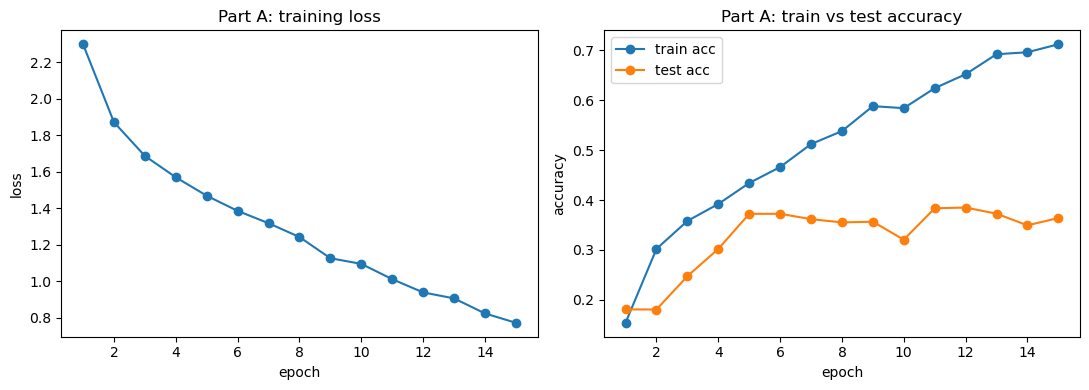

Part A | train acc 0.7120 | test acc 0.3639 | gap 0.3481


In [7]:
import os, json
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
epochs = range(1, EPOCHS_A + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(epochs, hist_a["train_loss"], marker="o")
ax[0].set_title("Part A: training loss")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss")

ax[1].plot(epochs, hist_a["train_acc"], marker="o", label="train acc")
ax[1].plot(epochs, hist_a["test_acc"], marker="o", label="test acc")
ax[1].set_title("Part A: train vs test accuracy")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].legend()

plt.tight_layout()
plt.savefig("figures/partA_curves.png", dpi=150)
plt.show()

final_train, final_test = hist_a["train_acc"][-1], hist_a["test_acc"][-1]
print(f"Part A | train acc {final_train:.4f} | test acc {final_test:.4f} | gap {final_train - final_test:.4f}")

# Start METRICS.md and keep results in json for later parts
results = {"A_supervised": {"train_acc": final_train, "test_acc": final_test, "epochs": EPOCHS_A}}
json.dump(results, open("results.json", "w"), indent=2)

with open("METRICS.md", "w") as f:
    f.write("# Metrics\n\n")
    f.write(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}\n\n")
    f.write("| Method | Epochs | Final train acc | Final test acc |\n|---|---|---|---|\n")
    f.write(f"| A: Supervised (500 labels) | {EPOCHS_A} | {final_train:.4f} | {final_test:.4f} |\n")

### Load unlabeled data and define the model

In [8]:
import time
from torchvision.models import resnet18

# Unlabeled images as one uint8 tensor (100000, 3, 96, 96), kept on CPU
unlab_x = torch.from_numpy(unlab_ds.data)
print("unlabeled tensor:", tuple(unlab_x.shape), unlab_x.dtype)

mean_t = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
std_t  = torch.tensor(STD,  device=device).view(1, 3, 1, 1)

def make_rotation_batch(xb):
    """xb: uint8 batch on GPU (B,3,96,96). Returns 4B images and rotation labels 0..3."""
    xb = (xb.float() / 255.0 - mean_t) / std_t
    flip = torch.rand(xb.size(0), device=xb.device) < 0.5
    xb = torch.where(flip.view(-1, 1, 1, 1), xb.flip(3), xb)
    imgs = torch.cat([torch.rot90(xb, k, dims=(2, 3)) for k in range(4)], dim=0)
    labels = torch.arange(4, device=xb.device).repeat_interleave(xb.size(0))
    return imgs, labels

class RotNet(nn.Module):
    def __init__(self):
        super().__init__()
        enc = resnet18(weights=None)        # no pretrained weights
        enc.fc = nn.Identity()              # encoder outputs 512 dim features
        self.encoder = enc
        self.rot_head = nn.Linear(512, 4)   # rotation head, removed after training
    def forward(self, x):
        return self.rot_head(self.encoder(x))

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
model_b = RotNet().to(device)
print("params:", sum(p.numel() for p in model_b.parameters()))

unlabeled tensor: (100000, 3, 96, 96) torch.uint8
params: 11178564


## PartB

### B.1. Train the rotation task

In [9]:
EPOCHS_B = 15
BATCH_B = 64            # 64 images become 256 rotated images per step
N = unlab_x.size(0)

opt_b = torch.optim.Adam(model_b.parameters(), lr=1e-3, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
loss_fn = nn.CrossEntropyLoss()
hist_b = {"loss": [], "rot_acc": []}

g_b = torch.Generator().manual_seed(SEED)

for epoch in range(1, EPOCHS_B + 1):
    model_b.train()
    perm = torch.randperm(N, generator=g_b)
    run_loss = correct = total = 0
    t0 = time.time()
    for i in range(0, N - BATCH_B + 1, BATCH_B):
        xb = unlab_x[perm[i:i + BATCH_B]].to(device, non_blocking=True)
        imgs, rot_y = make_rotation_batch(xb)
        opt_b.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            out = model_b(imgs)
            loss = loss_fn(out, rot_y)
        scaler.scale(loss).backward()
        scaler.step(opt_b)
        scaler.update()
        run_loss += loss.item() * rot_y.size(0)
        correct += (out.argmax(1) == rot_y).sum().item()
        total += rot_y.size(0)
    hist_b["loss"].append(run_loss / total); hist_b["rot_acc"].append(correct / total)
    print(f"{time.strftime('%H:%M:%S')} epoch {epoch:2d} | rot loss {run_loss/total:.3f} | rot acc {correct/total:.3f} | {time.time()-t0:.0f}s")

torch.save(model_b.encoder.state_dict(), "resnet18_rotation_encoder.pt")
print("saved encoder only, rotation head dropped")

20:40:05 epoch  1 | rot loss 0.712 | rot acc 0.717 | 109s
20:41:50 epoch  2 | rot loss 0.510 | rot acc 0.805 | 105s
20:43:36 epoch  3 | rot loss 0.435 | rot acc 0.836 | 106s
20:45:21 epoch  4 | rot loss 0.388 | rot acc 0.854 | 105s
20:47:08 epoch  5 | rot loss 0.359 | rot acc 0.866 | 107s
20:48:54 epoch  6 | rot loss 0.337 | rot acc 0.875 | 106s
20:50:40 epoch  7 | rot loss 0.321 | rot acc 0.881 | 107s
20:52:26 epoch  8 | rot loss 0.307 | rot acc 0.887 | 106s
20:54:11 epoch  9 | rot loss 0.295 | rot acc 0.891 | 105s
20:55:58 epoch 10 | rot loss 0.286 | rot acc 0.895 | 107s
20:57:44 epoch 11 | rot loss 0.281 | rot acc 0.897 | 106s
20:59:30 epoch 12 | rot loss 0.274 | rot acc 0.900 | 107s
21:01:16 epoch 13 | rot loss 0.269 | rot acc 0.901 | 105s
21:03:01 epoch 14 | rot loss 0.264 | rot acc 0.903 | 105s
21:04:46 epoch 15 | rot loss 0.259 | rot acc 0.905 | 105s
saved encoder only, rotation head dropped


### Linear classifier on the frozen encoder

In [10]:
def linear_eval(encoder_path, name, epochs=20, lr=1e-3):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

    # Load the pretrained encoder and freeze it
    enc = resnet18(weights=None)
    enc.fc = nn.Identity()
    enc.load_state_dict(torch.load(encoder_path, map_location=device))
    enc = enc.to(device)
    for p in enc.parameters():
        p.requires_grad = False
    enc.eval()                                   # keeps BatchNorm statistics fixed too

    # Fingerprint of the encoder, to prove it did not change
    fingerprint = lambda m: sum(v.double().sum().item() for v in m.state_dict().values())
    before = fingerprint(enc)

    head = nn.Linear(512, 10).to(device)         # the only part that learns
    opt = torch.optim.Adam(head.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    full = nn.Sequential(enc, head)

    # Same 500 images as Part A, same augmentation
    loader = DataLoader(Subset(train_aug, subset_idx), batch_size=64, shuffle=True,
                        num_workers=2, generator=torch.Generator().manual_seed(SEED))

    print("trainable params:", sum(p.numel() for p in full.parameters() if p.requires_grad))
    hist = {"train_loss": [], "train_acc": [], "test_acc": []}

    for epoch in range(1, epochs + 1):
        run_loss = correct = total = 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.no_grad():
                feats = enc(x)
            out = head(feats)
            loss = loss_fn(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            run_loss += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
        te_acc = evaluate(full, test_loader)
        hist["train_loss"].append(run_loss / total); hist["train_acc"].append(correct / total); hist["test_acc"].append(te_acc)
        print(f"{time.strftime('%H:%M:%S')} epoch {epoch:2d} | loss {run_loss/total:.3f} | train acc {correct/total:.3f} | test acc {te_acc:.3f}")

    after = fingerprint(enc)
    print("encoder unchanged:", before == after)
    torch.save(full.state_dict(), f"{name}_linear_model.pt")
    return hist

EPOCHS_B_LIN = 20
hist_b_lin = linear_eval("resnet18_rotation_encoder.pt", "rotation", epochs=EPOCHS_B_LIN)
print("Part B final test accuracy:", hist_b_lin["test_acc"][-1])

# Save results
results = json.load(open("results.json"))
results["B_rotation"] = {"train_acc": hist_b_lin["train_acc"][-1], "test_acc": hist_b_lin["test_acc"][-1],
                         "epochs_pretrain": EPOCHS_B, "epochs_linear": EPOCHS_B_LIN,
                         "rotation_acc": hist_b["rot_acc"][-1]}
json.dump(results, open("results.json", "w"), indent=2)
with open("METRICS.md", "a") as f:
    f.write(f"| B: Rotation SSL + linear (500 labels) | {EPOCHS_B} pretrain + {EPOCHS_B_LIN} linear | {hist_b_lin['train_acc'][-1]:.4f} | {hist_b_lin['test_acc'][-1]:.4f} |\n")

trainable params: 5130
21:12:35 epoch  1 | loss 2.314 | train acc 0.090 | test acc 0.094
21:13:10 epoch  2 | loss 2.296 | train acc 0.092 | test acc 0.096
21:13:45 epoch  3 | loss 2.282 | train acc 0.098 | test acc 0.098
21:14:19 epoch  4 | loss 2.271 | train acc 0.102 | test acc 0.136
21:14:57 epoch  5 | loss 2.260 | train acc 0.140 | test acc 0.141
21:15:34 epoch  6 | loss 2.248 | train acc 0.150 | test acc 0.144
21:16:11 epoch  7 | loss 2.244 | train acc 0.176 | test acc 0.141
21:16:48 epoch  8 | loss 2.242 | train acc 0.158 | test acc 0.147
21:17:24 epoch  9 | loss 2.229 | train acc 0.166 | test acc 0.159
21:18:01 epoch 10 | loss 2.224 | train acc 0.172 | test acc 0.157
21:18:37 epoch 11 | loss 2.220 | train acc 0.182 | test acc 0.157
21:19:13 epoch 12 | loss 2.208 | train acc 0.182 | test acc 0.164
21:19:51 epoch 13 | loss 2.204 | train acc 0.188 | test acc 0.164
21:20:30 epoch 14 | loss 2.194 | train acc 0.226 | test acc 0.170
21:21:07 epoch 15 | loss 2.187 | train acc 0.194 | te

## Part B Result: Rotation SSL + Linear Classifier (lr 1e-3)

**Result**
Test accuracy was 19.2% (0.1921), lower than the Part A supervised baseline of 36.4%.

**Setup check**
| Check | Output | Meaning |
|---|---|---|
| Trainable params | 5130 | Only the linear layer (512 x 10 weights + 10 biases) was updated |
| Encoder unchanged | True | The encoder stayed frozen during linear evaluation |

**What the numbers show**
- Training loss went only from 2.314 to 2.162 over 20 epochs. Random guessing over 10 classes gives a loss of about 2.30, so the linear layer barely learned.
- Train accuracy ended at 21.8%, close to the test accuracy. This is not overfitting. The classifier is undertrained.

**Hypothesis**
The learning rate of 1e-3 is too low for a single linear layer on top of these features, so the classifier had not finished learning. This means the 19.2% does not yet show how good the rotation features are. I will test it by rerunning with lr 1e-2, choosing the rate by training loss and train accuracy, not by test accuracy, so the test set is not used for tuning.

**Reporting**
Both runs (lr 1e-3 and lr 1e-2) will be kept and reported

In [11]:
hist_b_lin2 = linear_eval("resnet18_rotation_encoder.pt", "rotation_lr1e-2", epochs=20, lr=1e-2)
print("Part B (lr 1e-2) final test accuracy:", hist_b_lin2["test_acc"][-1])

results = json.load(open("results.json"))
results["B_rotation_lr1e-2"] = {"train_acc": hist_b_lin2["train_acc"][-1], "test_acc": hist_b_lin2["test_acc"][-1],
                                "epochs_pretrain": EPOCHS_B, "epochs_linear": 20, "lr": 1e-2}
json.dump(results, open("results.json", "w"), indent=2)
with open("METRICS.md", "a") as f:
    f.write(f"| B: Rotation SSL + linear, lr 1e-2 (500 labels) | {EPOCHS_B} pretrain + 20 linear | {hist_b_lin2['train_acc'][-1]:.4f} | {hist_b_lin2['test_acc'][-1]:.4f} |\n")

trainable params: 5130
21:29:54 epoch  1 | loss 2.300 | train acc 0.142 | test acc 0.154
21:30:29 epoch  2 | loss 2.209 | train acc 0.184 | test acc 0.178
21:31:05 epoch  3 | loss 2.160 | train acc 0.250 | test acc 0.223
21:31:41 epoch  4 | loss 2.127 | train acc 0.236 | test acc 0.213
21:32:16 epoch  5 | loss 2.091 | train acc 0.268 | test acc 0.249
21:32:53 epoch  6 | loss 2.051 | train acc 0.284 | test acc 0.269
21:33:33 epoch  7 | loss 2.039 | train acc 0.282 | test acc 0.250
21:34:11 epoch  8 | loss 2.031 | train acc 0.290 | test acc 0.306
21:34:48 epoch  9 | loss 2.007 | train acc 0.296 | test acc 0.319
21:35:27 epoch 10 | loss 1.973 | train acc 0.314 | test acc 0.284
21:36:04 epoch 11 | loss 1.972 | train acc 0.316 | test acc 0.331
21:36:42 epoch 12 | loss 1.951 | train acc 0.360 | test acc 0.343
21:37:19 epoch 13 | loss 1.932 | train acc 0.328 | test acc 0.315
21:37:59 epoch 14 | loss 1.910 | train acc 0.316 | test acc 0.341
21:38:39 epoch 15 | loss 1.889 | train acc 0.378 | te

## Part C, SimCLR pretraining

In [4]:
import time, json
from torchvision.models import resnet18

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        total += y.size(0)
    return correct / total

print("restored")

restored


The above code is run because the jupyter code restarted

### Data, augmentations, model, loss

In [5]:
from PIL import Image

# 20,000 unlabeled images, chosen with SEED, copied into their own small array
c_idx = np.random.RandomState(SEED).choice(len(unlab_ds), 20000, replace=False)
c_data = np.ascontiguousarray(unlab_ds.data[c_idx])      # (20000, 3, 96, 96) uint8
print("SimCLR subset:", c_data.shape)

simclr_tf = T.Compose([
    T.RandomResizedCrop(96, scale=(0.2, 1.0)),                         # 1: crop
    T.RandomHorizontalFlip(),                                          # 2: flip
    T.RandomApply([T.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),         # 3: color jitter
    T.RandomGrayscale(p=0.2),                                          # 4: grayscale
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

class TwoViewDataset(torch.utils.data.Dataset):
    def __init__(self, arr, tf):
        self.arr, self.tf = arr, tf
    def __len__(self):
        return len(self.arr)
    def __getitem__(self, i):
        img = Image.fromarray(np.transpose(self.arr[i], (1, 2, 0)))
        return self.tf(img), self.tf(img)          # two random views of the same image

BATCH_C = 256
NUM_WORKERS = 0      # start at 0, it cannot hang. Raise only if epochs are too slow.
g_c = torch.Generator().manual_seed(SEED)
simclr_loader = DataLoader(TwoViewDataset(c_data, simclr_tf), batch_size=BATCH_C, shuffle=True,
                           num_workers=NUM_WORKERS, drop_last=True, generator=g_c)

class SimCLR(nn.Module):
    def __init__(self):
        super().__init__()
        enc = resnet18(weights=None)          # no pretrained weights
        enc.fc = nn.Identity()
        self.encoder = enc
        self.proj = nn.Sequential(nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 128))  # projection head
    def forward(self, x):
        return self.proj(self.encoder(x))

TAU = 0.2

def nt_xent(z1, z2, tau=TAU):
    """z1, z2: (B,128) embeddings of the two views. Uses cosine similarity."""
    B = z1.size(0)
    z = F.normalize(torch.cat([z1, z2], dim=0).float(), dim=1)   # unit length, so dot product = cosine
    sim = z @ z.t() / tau                                        # (2B, 2B)
    sim = sim.masked_fill(torch.eye(2 * B, dtype=torch.bool, device=z.device), -1e9)  # ignore self
    targets = torch.cat([torch.arange(B, 2 * B), torch.arange(0, B)]).to(z.device)    # positive partner
    loss = F.cross_entropy(sim, targets)
    acc = (sim.argmax(1) == targets).float().mean().item()       # how often the true partner ranks first
    return loss, acc

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
model_c = SimCLR().to(device)
print("pairs per epoch:", len(simclr_loader) * BATCH_C, "| batches:", len(simclr_loader))

# Speed test: load 3 batches and time them
t = time.time()
for i, (v1, v2) in enumerate(simclr_loader):
    print(i, tuple(v1.shape), f"{time.time()-t:.1f}s")
    if i == 2:
        break

SimCLR subset: (20000, 3, 96, 96)
pairs per epoch: 19968 | batches: 78
0 (256, 3, 96, 96) 2.1s
1 (256, 3, 96, 96) 4.0s
2 (256, 3, 96, 96) 6.0s


### Train for 20 epochs

In [6]:
EPOCHS_C = 20

# Reset seeds so the speed test above does not change the run
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
g_c.manual_seed(SEED)

opt_c = torch.optim.Adam(model_c.parameters(), lr=1e-3, weight_decay=1e-4)
scaler_c = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
hist_c = {"loss": [], "pos_acc": []}

for epoch in range(1, EPOCHS_C + 1):
    model_c.train()
    run_loss = run_acc = n = 0
    t0 = time.time()
    for v1, v2 in simclr_loader:
        v1, v2 = v1.to(device, non_blocking=True), v2.to(device, non_blocking=True)
        opt_c.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            z = model_c(torch.cat([v1, v2], dim=0))
        loss, acc = nt_xent(z[:v1.size(0)], z[v1.size(0):])
        scaler_c.scale(loss).backward()
        scaler_c.step(opt_c)
        scaler_c.update()
        run_loss += loss.item(); run_acc += acc; n += 1
    hist_c["loss"].append(run_loss / n); hist_c["pos_acc"].append(run_acc / n)
    print(f"{time.strftime('%H:%M:%S')} epoch {epoch:2d} | loss {run_loss/n:.3f} | pos acc {run_acc/n:.3f} | {time.time()-t0:.0f}s")

torch.save(model_c.encoder.state_dict(), "resnet18_simclr_encoder.pt")   # encoder only, projection head dropped
print("saved encoder only, projection head dropped")

00:12:52 epoch  1 | loss 5.364 | pos acc 0.043 | 178s
00:15:44 epoch  2 | loss 4.584 | pos acc 0.120 | 172s
00:18:47 epoch  3 | loss 4.182 | pos acc 0.207 | 183s
00:21:54 epoch  4 | loss 3.847 | pos acc 0.321 | 187s
00:25:01 epoch  5 | loss 3.653 | pos acc 0.394 | 187s
00:28:05 epoch  6 | loss 3.508 | pos acc 0.460 | 184s
00:31:10 epoch  7 | loss 3.393 | pos acc 0.516 | 185s
00:34:14 epoch  8 | loss 3.317 | pos acc 0.548 | 184s
00:37:19 epoch  9 | loss 3.240 | pos acc 0.583 | 184s
00:40:22 epoch 10 | loss 3.187 | pos acc 0.607 | 183s
00:43:25 epoch 11 | loss 3.149 | pos acc 0.624 | 183s
00:46:29 epoch 12 | loss 3.105 | pos acc 0.638 | 184s
00:49:29 epoch 13 | loss 3.076 | pos acc 0.654 | 180s
00:52:27 epoch 14 | loss 3.020 | pos acc 0.679 | 178s
00:55:25 epoch 15 | loss 3.002 | pos acc 0.692 | 178s
00:58:18 epoch 16 | loss 2.959 | pos acc 0.708 | 173s
01:01:16 epoch 17 | loss 2.953 | pos acc 0.707 | 178s
01:04:11 epoch 18 | loss 2.927 | pos acc 0.719 | 175s
01:07:03 epoch 19 | loss 2.9

In [9]:
def linear_eval(encoder_path, name, epochs=20, lr=1e-3):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

    # Load the pretrained encoder and freeze it
    enc = resnet18(weights=None)
    enc.fc = nn.Identity()
    enc.load_state_dict(torch.load(encoder_path, map_location=device))
    enc = enc.to(device)
    for p in enc.parameters():
        p.requires_grad = False
    enc.eval()                                   # keeps BatchNorm statistics fixed too

    # Fingerprint of the encoder, to prove it did not change
    fingerprint = lambda m: sum(v.double().sum().item() for v in m.state_dict().values())
    before = fingerprint(enc)

    head = nn.Linear(512, 10).to(device)         # the only part that learns
    opt = torch.optim.Adam(head.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    full = nn.Sequential(enc, head)

    # Same 500 images as Part A, same augmentation
    loader = DataLoader(Subset(train_aug, subset_idx), batch_size=64, shuffle=True,
                        num_workers=2, generator=torch.Generator().manual_seed(SEED))

    print("trainable params:", sum(p.numel() for p in full.parameters() if p.requires_grad))
    hist = {"train_loss": [], "train_acc": [], "test_acc": []}

    for epoch in range(1, epochs + 1):
        run_loss = correct = total = 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.no_grad():
                feats = enc(x)
            out = head(feats)
            loss = loss_fn(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            run_loss += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
        te_acc = evaluate(full, test_loader)
        hist["train_loss"].append(run_loss / total); hist["train_acc"].append(correct / total); hist["test_acc"].append(te_acc)
        print(f"{time.strftime('%H:%M:%S')} epoch {epoch:2d} | loss {run_loss/total:.3f} | train acc {correct/total:.3f} | test acc {te_acc:.3f}")

    after = fingerprint(enc)
    print("encoder unchanged:", before == after)
    torch.save(full.state_dict(), f"{name}_linear_model.pt")
    return hist

print("linear_eval defined")

linear_eval defined


### Linear classifier on the frozen SimCLR encoder

In [10]:
EPOCHS_C = 20
EPOCHS_C_LIN = 20
hist_c_lin = linear_eval("resnet18_simclr_encoder.pt", "simclr", epochs=EPOCHS_C_LIN, lr=1e-2)
print("Part C final test accuracy:", hist_c_lin["test_acc"][-1])

pre = globals().get("hist_c")   # pretraining history, may be gone after a restart
pre_loss = pre["loss"][-1] if pre else 2.882        # from the printed log
pre_pos  = pre["pos_acc"][-1] if pre else 0.738     # from the printed log

results = json.load(open("results.json"))
results["C_simclr"] = {"train_acc": hist_c_lin["train_acc"][-1], "test_acc": hist_c_lin["test_acc"][-1],
                       "epochs_pretrain": EPOCHS_C, "epochs_linear": EPOCHS_C_LIN, "lr": 1e-2,
                       "pretrain_loss": pre_loss, "pretrain_pos_acc": pre_pos}
json.dump(results, open("results.json", "w"), indent=2)
with open("METRICS.md", "a") as f:
    f.write(f"| C: SimCLR + linear, lr 1e-2 (500 labeled images) | {EPOCHS_C} pretrain + {EPOCHS_C_LIN} linear | {hist_c_lin['train_acc'][-1]:.4f} | {hist_c_lin['test_acc'][-1]:.4f} |\n")

trainable params: 5130
01:25:31 epoch  1 | loss 2.107 | train acc 0.266 | test acc 0.444
01:26:05 epoch  2 | loss 1.473 | train acc 0.510 | test acc 0.481
01:26:39 epoch  3 | loss 1.356 | train acc 0.536 | test acc 0.531
01:27:13 epoch  4 | loss 1.207 | train acc 0.576 | test acc 0.485
01:27:47 epoch  5 | loss 1.192 | train acc 0.578 | test acc 0.501
01:28:21 epoch  6 | loss 1.143 | train acc 0.610 | test acc 0.523
01:28:54 epoch  7 | loss 1.088 | train acc 0.588 | test acc 0.501
01:29:28 epoch  8 | loss 1.030 | train acc 0.616 | test acc 0.508
01:30:01 epoch  9 | loss 0.993 | train acc 0.632 | test acc 0.524
01:30:37 epoch 10 | loss 1.025 | train acc 0.618 | test acc 0.513
01:31:10 epoch 11 | loss 0.952 | train acc 0.644 | test acc 0.531
01:31:44 epoch 12 | loss 0.924 | train acc 0.648 | test acc 0.545
01:32:17 epoch 13 | loss 0.877 | train acc 0.662 | test acc 0.533
01:32:51 epoch 14 | loss 0.919 | train acc 0.658 | test acc 0.537
01:33:24 epoch 15 | loss 0.885 | train acc 0.688 | te

## Part D, nearest neighbor visualization

### Embeddings and a number for each encoder

In [11]:
import matplotlib.pyplot as plt

def load_encoder(path, supervised=False):
    if supervised:
        m = resnet18(weights=None, num_classes=10)      # Part A model, had a 10 class layer
        m.load_state_dict(torch.load(path, map_location=device))
    else:
        m = resnet18(weights=None)
        m.fc = nn.Identity()
        m.load_state_dict(torch.load(path, map_location=device))
    m.fc = nn.Identity()                                # keep only the 512 number embedding
    return m.to(device).eval()

@torch.no_grad()
def extract(model):
    feats = []
    for x, _ in test_loader:                            # test images, no augmentation, fixed order
        feats.append(model(x.to(device)).float().cpu())
    return F.normalize(torch.cat(feats), dim=1)         # length 1, so dot product = cosine similarity

encoder_files = {
    "Supervised":   ("resnet18_supervised.pt", True),
    "Rotation SSL": ("resnet18_rotation_encoder.pt", False),
    "SimCLR":       ("resnet18_simclr_encoder.pt", False),
}
emb = {name: extract(load_encoder(p, sup)) for name, (p, sup) in encoder_files.items()}
test_labels = np.array(test_ds.labels)
print({k: tuple(v.shape) for k, v in emb.items()})

# Top 5 neighbors for every test image (cosine similarity, the image itself excluded)
def knn_topk(f, k=5):
    out = []
    for i in range(0, f.size(0), 1000):
        s = f[i:i+1000] @ f.t()
        s[torch.arange(s.size(0)), torch.arange(i, i + s.size(0))] = -2
        out.append(s.topk(k, dim=1).indices)
    return torch.cat(out).numpy()

knn_result = {}
for name, f in emb.items():
    nn_idx = knn_topk(f)
    knn_result[name] = float((test_labels[nn_idx] == test_labels[:, None]).mean())
    print(f"{name:13s} top 5 neighbor precision: {knn_result[name]:.4f}")

results = json.load(open("results.json"))
results["D_top5_neighbor_precision"] = knn_result
json.dump(results, open("results.json", "w"), indent=2)
with open("METRICS.md", "a") as f:
    f.write("\n| Encoder | Top 5 neighbor precision (all 8000 test images) |\n|---|---|\n")
    for k, v in knn_result.items():
        f.write(f"| {k} | {v:.4f} |\n")

{'Supervised': (8000, 512), 'Rotation SSL': (8000, 512), 'SimCLR': (8000, 512)}
Supervised    top 5 neighbor precision: 0.3670
Rotation SSL  top 5 neighbor precision: 0.3352
SimCLR        top 5 neighbor precision: 0.4819


### Pictures, same query images for all three encoders

query indices: [4455, 3633, 1579, 6186] | classes: ['truck', 'deer', 'monkey', 'bird']


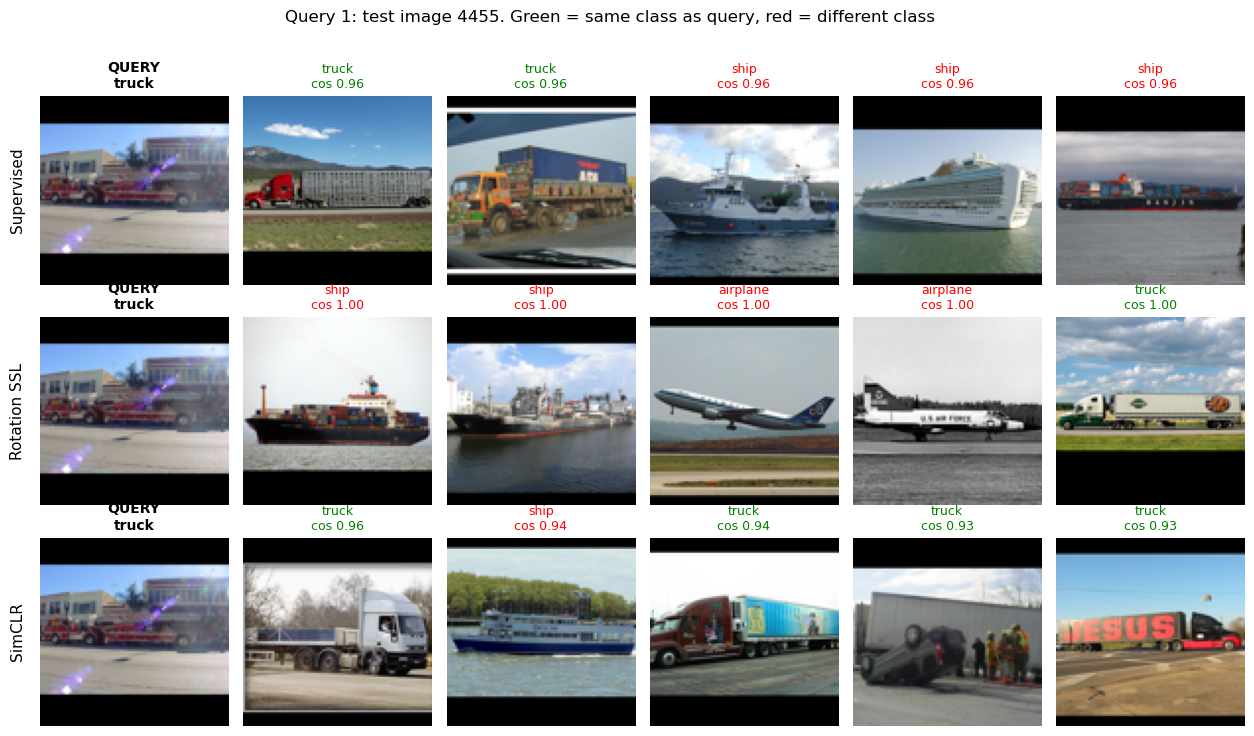

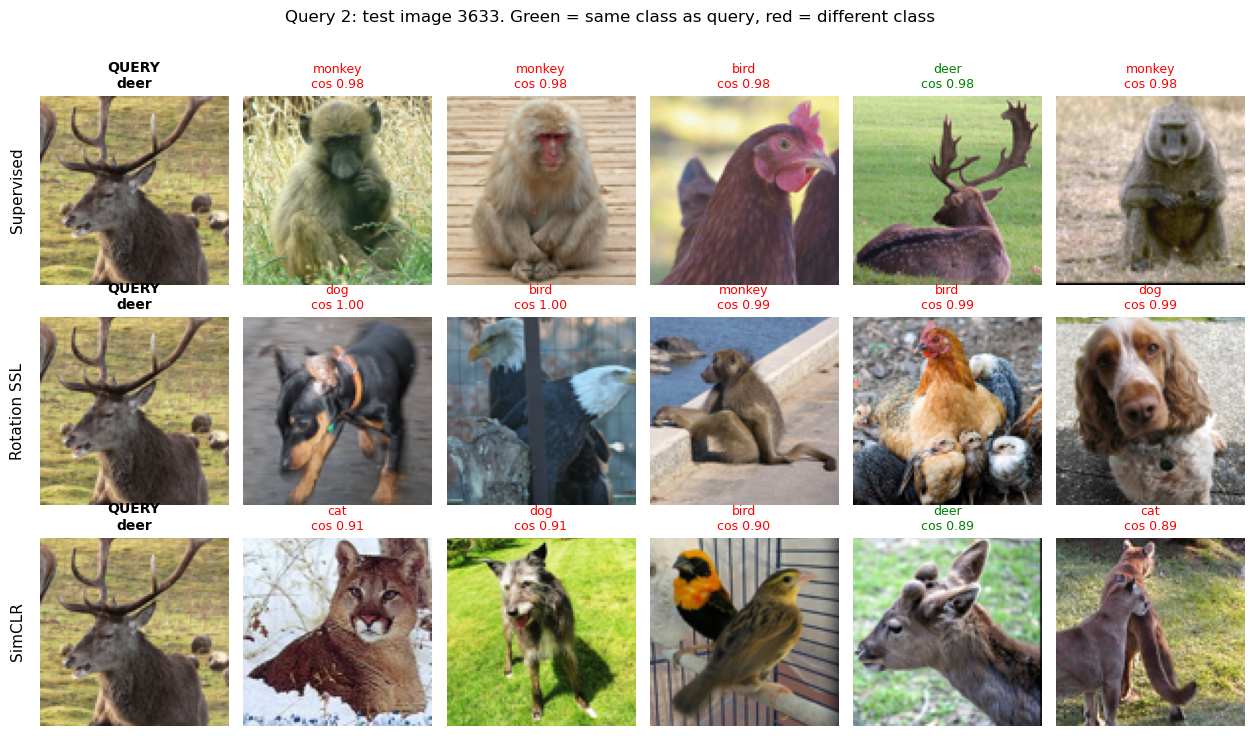

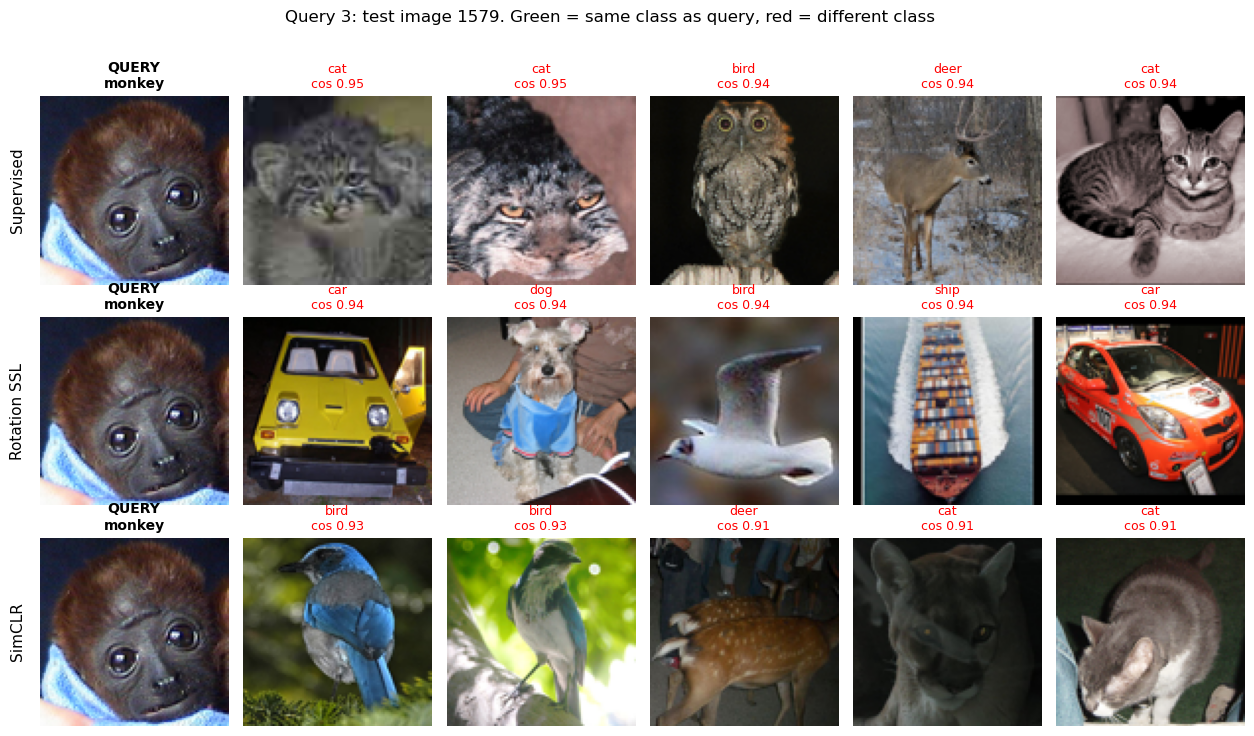

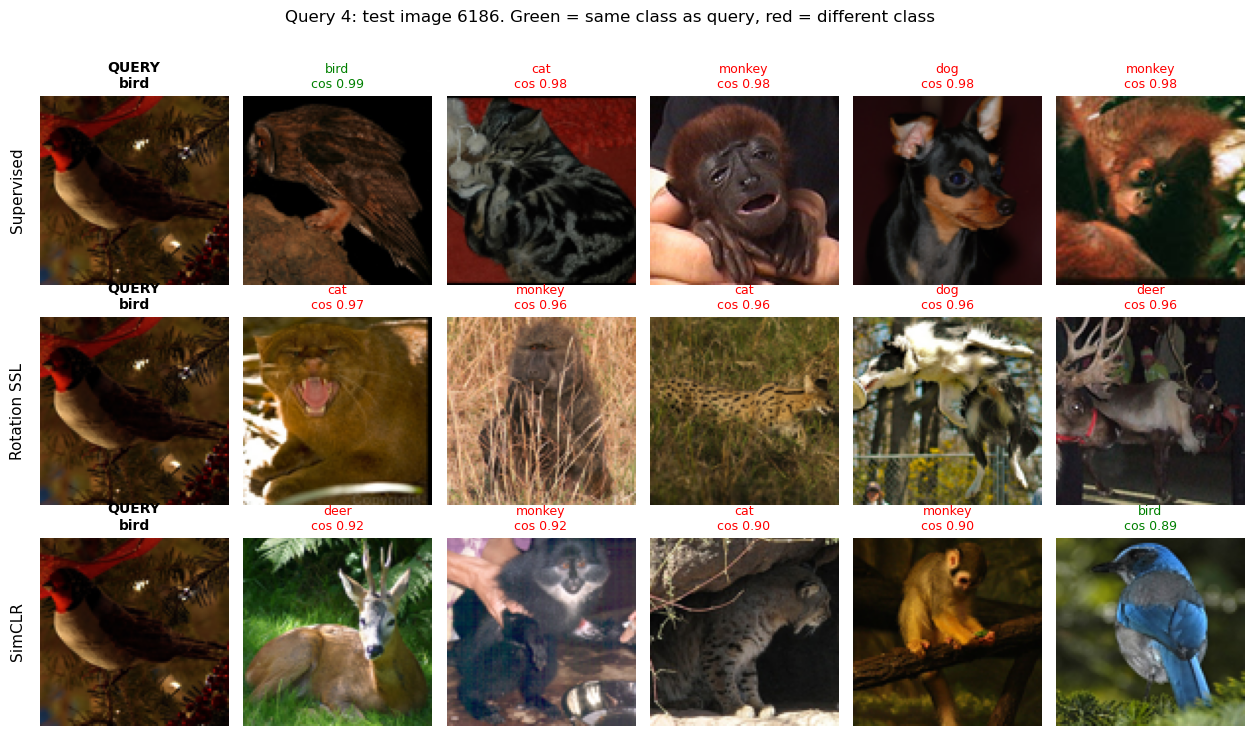

In [12]:
os.makedirs("figures", exist_ok=True)

# 4 queries from 4 different classes, chosen with SEED (the assignment needs at least 3)
rng = np.random.RandomState(SEED)
q_classes = rng.choice(10, 4, replace=False)
query_idx = [int(rng.choice(np.where(test_labels == c)[0])) for c in q_classes]
print("query indices:", query_idx, "| classes:", [classes[c] for c in q_classes])

def show_query(qi, n):
    fig, axes = plt.subplots(3, 6, figsize=(13, 7.5))
    for r, name in enumerate(emb):
        sims = emb[name] @ emb[name][qi]                # cosine similarity to every test image
        sims[qi] = -2                                   # exclude the query itself
        top = sims.topk(5).indices.tolist()
        for c, j in enumerate([qi] + top):
            ax = axes[r, c]
            ax.imshow(test_ds[j][0]); ax.axis("off")
            if c == 0:
                ax.set_title(f"QUERY\n{classes[test_labels[j]]}", fontsize=10, fontweight="bold")
                ax.text(-0.08, 0.5, name, transform=ax.transAxes, rotation=90, ha="right", va="center", fontsize=11)
            else:
                same = test_labels[j] == test_labels[qi]
                ax.set_title(f"{classes[test_labels[j]]}\ncos {sims[j]:.2f}", fontsize=9, color="green" if same else "red")
    fig.suptitle(f"Query {n}: test image {qi}. Green = same class as query, red = different class", fontsize=12)
    plt.tight_layout(rect=[0.03, 0, 1, 0.96])
    plt.savefig(f"figures/partD_query{n}.png", dpi=150)
    plt.show()

for n, qi in enumerate(query_idx, 1):
    show_query(qi, n)

### Which model performed the best?

SimCLR performed the best overall. It achieved the highest downstream test accuracy and the highest nearest-neighbor precision.

| Encoder | Test Accuracy | Top-5 Neighbor Precision |
|---|---:|---:|
| Supervised ResNet-18 | 36.39% | 36.70% |
| Rotation SSL | 37.63% | 33.52% |
| SimCLR | **53.20%** | **48.19%** |

SimCLR achieved 53.20% test accuracy using only a linear classifier trained on the same 500 labeled images used in Parts A and B. Its nearest-neighbor precision was also the highest, showing that its embedding space organized visually similar images more effectively.

SimCLR likely performed better because it learned to make two augmented views of the same image similar while separating views from different images. The augmentations changed the crop, color, and grayscale appearance, so the encoder had to learn stable features related to object identity and shape rather than relying only on background or color.

---

### Why did the supervised model perform worse?

The supervised model was trained end-to-end using only 500 labeled images. Its training accuracy reached 71.20%, but its test accuracy was only 36.39%. This large gap indicates overfitting.

Because the model had many parameters compared with the small number of labeled examples, it learned details specific to the training images instead of learning general features that transfer well to unseen images. The model had to learn both the visual representation and the class boundaries using very limited labeled data.

Possible improvements include:

- Using stronger data augmentation, such as random resized crops, color jitter, and random erasing.
- Applying label smoothing and stronger weight decay.
- Using a learning-rate scheduler or warm-up schedule.
- Using early stopping based on a validation set.
- Training a smaller model to reduce overfitting.
- Increasing the amount of labeled training data.
- Repeating the experiment with multiple random seeds.

---

### Why did the Rotation SSL model perform worse than SimCLR?

The rotation model learned the rotation prediction task successfully. Its rotation accuracy increased to 90.5%. However, its downstream test accuracy was only 37.63%, which was close to the supervised baseline and much lower than SimCLR.

The rotation task may be solvable using shortcuts. For example, the model could use the location of the sky, ground, horizon, or general image layout to predict the rotation. In that case, the model can achieve high rotation accuracy without learning features that distinguish visually similar object classes.

The rotation encoder also produced the lowest nearest-neighbor precision at 33.52%. This suggests that its embeddings were less aligned with semantic class similarity. Some neighbors may have shared similar backgrounds, colors, or layouts rather than the same object category.

Possible improvements include:

- Training the encoder for more epochs.
- Training the linear classifier longer.
- Using a learning-rate schedule for the linear classifier.
- Extracting features from intermediate ResNet layers.
- Combining rotation prediction with another self-supervised objective.
- Using augmentations that reduce orientation-based shortcuts.
- Using additional unlabeled data.
- Repeating the experiment with multiple random seeds.

---

### Why did SimCLR win even though its pretext accuracy was lower?

The rotation accuracy and SimCLR positive-pair accuracy measure different tasks, so they cannot be directly compared.

Rotation prediction is a 4-class classification problem: the model predicts whether the image was rotated by 0°, 90°, 180°, or 270°.

SimCLR requires the model to identify the correct augmented view among 511 possible candidates in the batch. Therefore, its positive-pair accuracy of 73.8% is measured on a much harder retrieval problem than the rotation task's 90.5% accuracy.

The fair comparison is the downstream linear-evaluation accuracy:

- Rotation SSL: 37.63%
- SimCLR: **53.20%**

This shows that SimCLR learned features that transferred better to the STL-10 classification task.

---

### What did the nearest-neighbor visualizations reveal?

The nearest-neighbor visualizations provided a qualitative view of the learned embedding spaces.

- **SimCLR produced the most semantically meaningful neighbors overall.** Its retrieved images were more likely to belong to the same class, especially for visually distinctive queries such as trucks.
- **The supervised encoder learned useful but less general features.** It sometimes retrieved related images, but it could also rely on background, color, and image appearance because it was trained on only 500 labeled examples.
- **The rotation encoder captured broad visual structure but struggled with fine-grained class distinctions.** It sometimes retrieved images with similar layouts or backgrounds instead of the same object class.
- **All three models captured some coarse visual similarity.** Vehicle images were often closer to other vehicle images, and animal images were often closer to other animals.
- **Fine-grained classification remained difficult.** Distinguishing between classes such as deer, dog, bird, and monkey was more challenging.
- **The monkey query was difficult for all three encoders**, demonstrating that even the best representation still had failure cases.

The aggregate top-5 precision values are more reliable than conclusions from only a few query images, but the visualizations help explain the types of errors made by each model. They show whether the embeddings are matching object identity or relying on superficial properties such as color, background, and image composition.

---

### Overall conclusion

The results show that self-supervised learning can improve image classification when labeled data is limited.

The supervised model reached 36.39% test accuracy but showed clear overfitting. Rotation SSL reached 37.63%, which was only a small improvement over the supervised baseline. SimCLR achieved the best result at 53.20% and also produced the highest nearest-neighbor precision at 48.19%.

Therefore, SimCLR learned the most useful and semantically organized representation. Its contrastive objective encouraged the model to preserve image identity across different augmentations while separating different images. With more time, I would pretrain SimCLR on all 100,000 unlabeled images, train for more epochs, use a larger effective batch size, apply a learning-rate schedule, and repeat the experiments across multiple random seeds.